# Django 4 Security and Performance

A practical guide to securing and optimizing Django 4 applications. Covers SSL/HTTPS setup, CSRF protection, SQL injection prevention, clickjacking defenses, host header validation, user-uploaded content verification, caching strategies, database query optimization, and template rendering performance.

## Table of Contents

- [Module 01: Introducing the Django Framework](#module-01-introducing-the-django-framework)
- [Module 02: Ensuring Security in Django 4](#module-02-ensuring-security-in-django-4)
- [Module 03: Optimizing Django 4 for Speed and Scalability](#module-03-optimizing-django-4-for-speed-and-scalability)
- [Module 04: Conclusion and Next Steps](#module-04-conclusion-and-next-steps)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Introducing the Django Framework

Django 4 is a high-level Python web framework that encourages rapid development and clean, pragmatic design. This module covers setting up a basic Django 4 application and deploying it to a cloud platform.

### Introducing Django 4

**What is Django?**
- A high-level Python web framework with batteries included
- Built-in authentication, admin interface, ORM, URL routing, templating, and security features
- Follows the Model-View-Template (MVT) pattern

**Why use Django?**
- Rapid development with reusable components
- Strong security defaults (CSRF, XSS, SQL injection protections)
- Extensive ecosystem and active community
- Scales well for production workloads

### Setting Up a Django 4 Application

**Prerequisites:**
1. Create a virtual environment to isolate dependencies
2. Install Django 4 inside the virtual environment
3. Create and run a new Django project

```bash
# Create and activate virtual environment
python3 -m venv venv
source venv/bin/activate  # macOS/Linux

# Install Django 4
pip install django

# Create a new project
django-admin startproject myproject
cd myproject

# Run the development server
python manage.py runserver
```

### Deploying Django to PythonAnywhere

PythonAnywhere is a cloud-based platform with preinstalled Python libraries. It offers a free tier suitable for learning, though not recommended for production or scalable applications.

**Deployment steps:**
1. Upload codebase to GitHub
2. Set up a web app at PythonAnywhere
3. Configure the Python virtual environment and WSGI file

### The FutureWatch Application

The FutureWatch app is a news platform used throughout this course as a real-world example. It includes:
- A landing page
- User authentication (login/signup)
- Reading news articles
- Publishing news articles

## Module 02: Ensuring Security in Django 4

This module covers the key security mechanisms available in Django 4: SSL/HTTPS, CSRF protection, SQL injection prevention, clickjacking defenses, host header validation, and verifying user-uploaded content.

### Deploying to a Linux Server

A typical production deployment stack for Django on Ubuntu:
- **Gunicorn** — a Python WSGI HTTP server that runs the Django application
- **Nginx** — a reverse proxy that sits in front of Gunicorn, handles static files and SSL termination
- **Custom domain** — pointed to the server IP via DNS

> In Linux the Root user has extensive privileges but should be used sparingly to avoid unintentional and potentially destructive actions.

**Deployment checklist:**
1. Configure Gunicorn socket and service files (`systemd`)
2. Configure Nginx as a reverse proxy to forward requests to Gunicorn
3. Point a custom domain to the server
4. Obtain and install an SSL certificate

### SSL and HTTPS in Django 4

**SSL (Secure Socket Layers)** enables secure, encrypted data communication between client and server.

**HTTPS (Hyper Text Transfer Protocol Secure)** builds on SSL — sites with a valid SSL certificate can serve content over HTTPS, which displays a lock icon in browsers.

SSL/HTTPS plays a crucial role in Django:
- Ensures sensitive information (passwords, tokens, personal data) is transmitted securely
- Obtain an SSL certificate from a trusted Certificate Authority (CA)
- It's like sending a secret message in a locked envelope

#### Configuring SSL in Django `settings.py`

```python
# Redirect all HTTP traffic to HTTPS
SECURE_SSL_REDIRECT = True

# Tell Django the request came in over HTTPS (when behind a proxy like Nginx)
SECURE_PROXY_SSL_HEADER = ('HTTP_X_FORWARDED_PROTO', 'https')

# Only send the session cookie over HTTPS
SESSION_COOKIE_SECURE = True

# Only send the CSRF cookie over HTTPS
CSRF_COOKIE_SECURE = True

# Include the domain in ALLOWED_HOSTS
ALLOWED_HOSTS = ['example.com', 'www.example.com']
```

#### Let's Encrypt and Certbot

**Let's Encrypt** is a nonprofit Certificate Authority providing SSL certificates free of cost.

**Certbot** is the recommended ACME client for obtaining and renewing Let's Encrypt certificates:
- Automates certificate issuance and installation
- Handles auto-renewal via a cron job or systemd timer
- Easy to use with great documentation

**Setup steps:**
1. Configure Nginx server block with your domain
2. Update Django settings (`SECURE_SSL_REDIRECT`, `SESSION_COOKIE_SECURE`, etc.)
3. Obtain SSL certificate: `sudo certbot --nginx -d example.com`
4. Verify auto-renewal: `sudo certbot renew --dry-run`

> Making security a top priority not only protects your users but also improves your online presence.

### CSRF Protection in Django 4

**CSRF (Cross-Site Request Forgery)** is a security vulnerability that allows unauthorized actions to be performed through browser manipulation — an attacker tricks a logged-in user's browser into submitting a request to a site the user is already authenticated with.


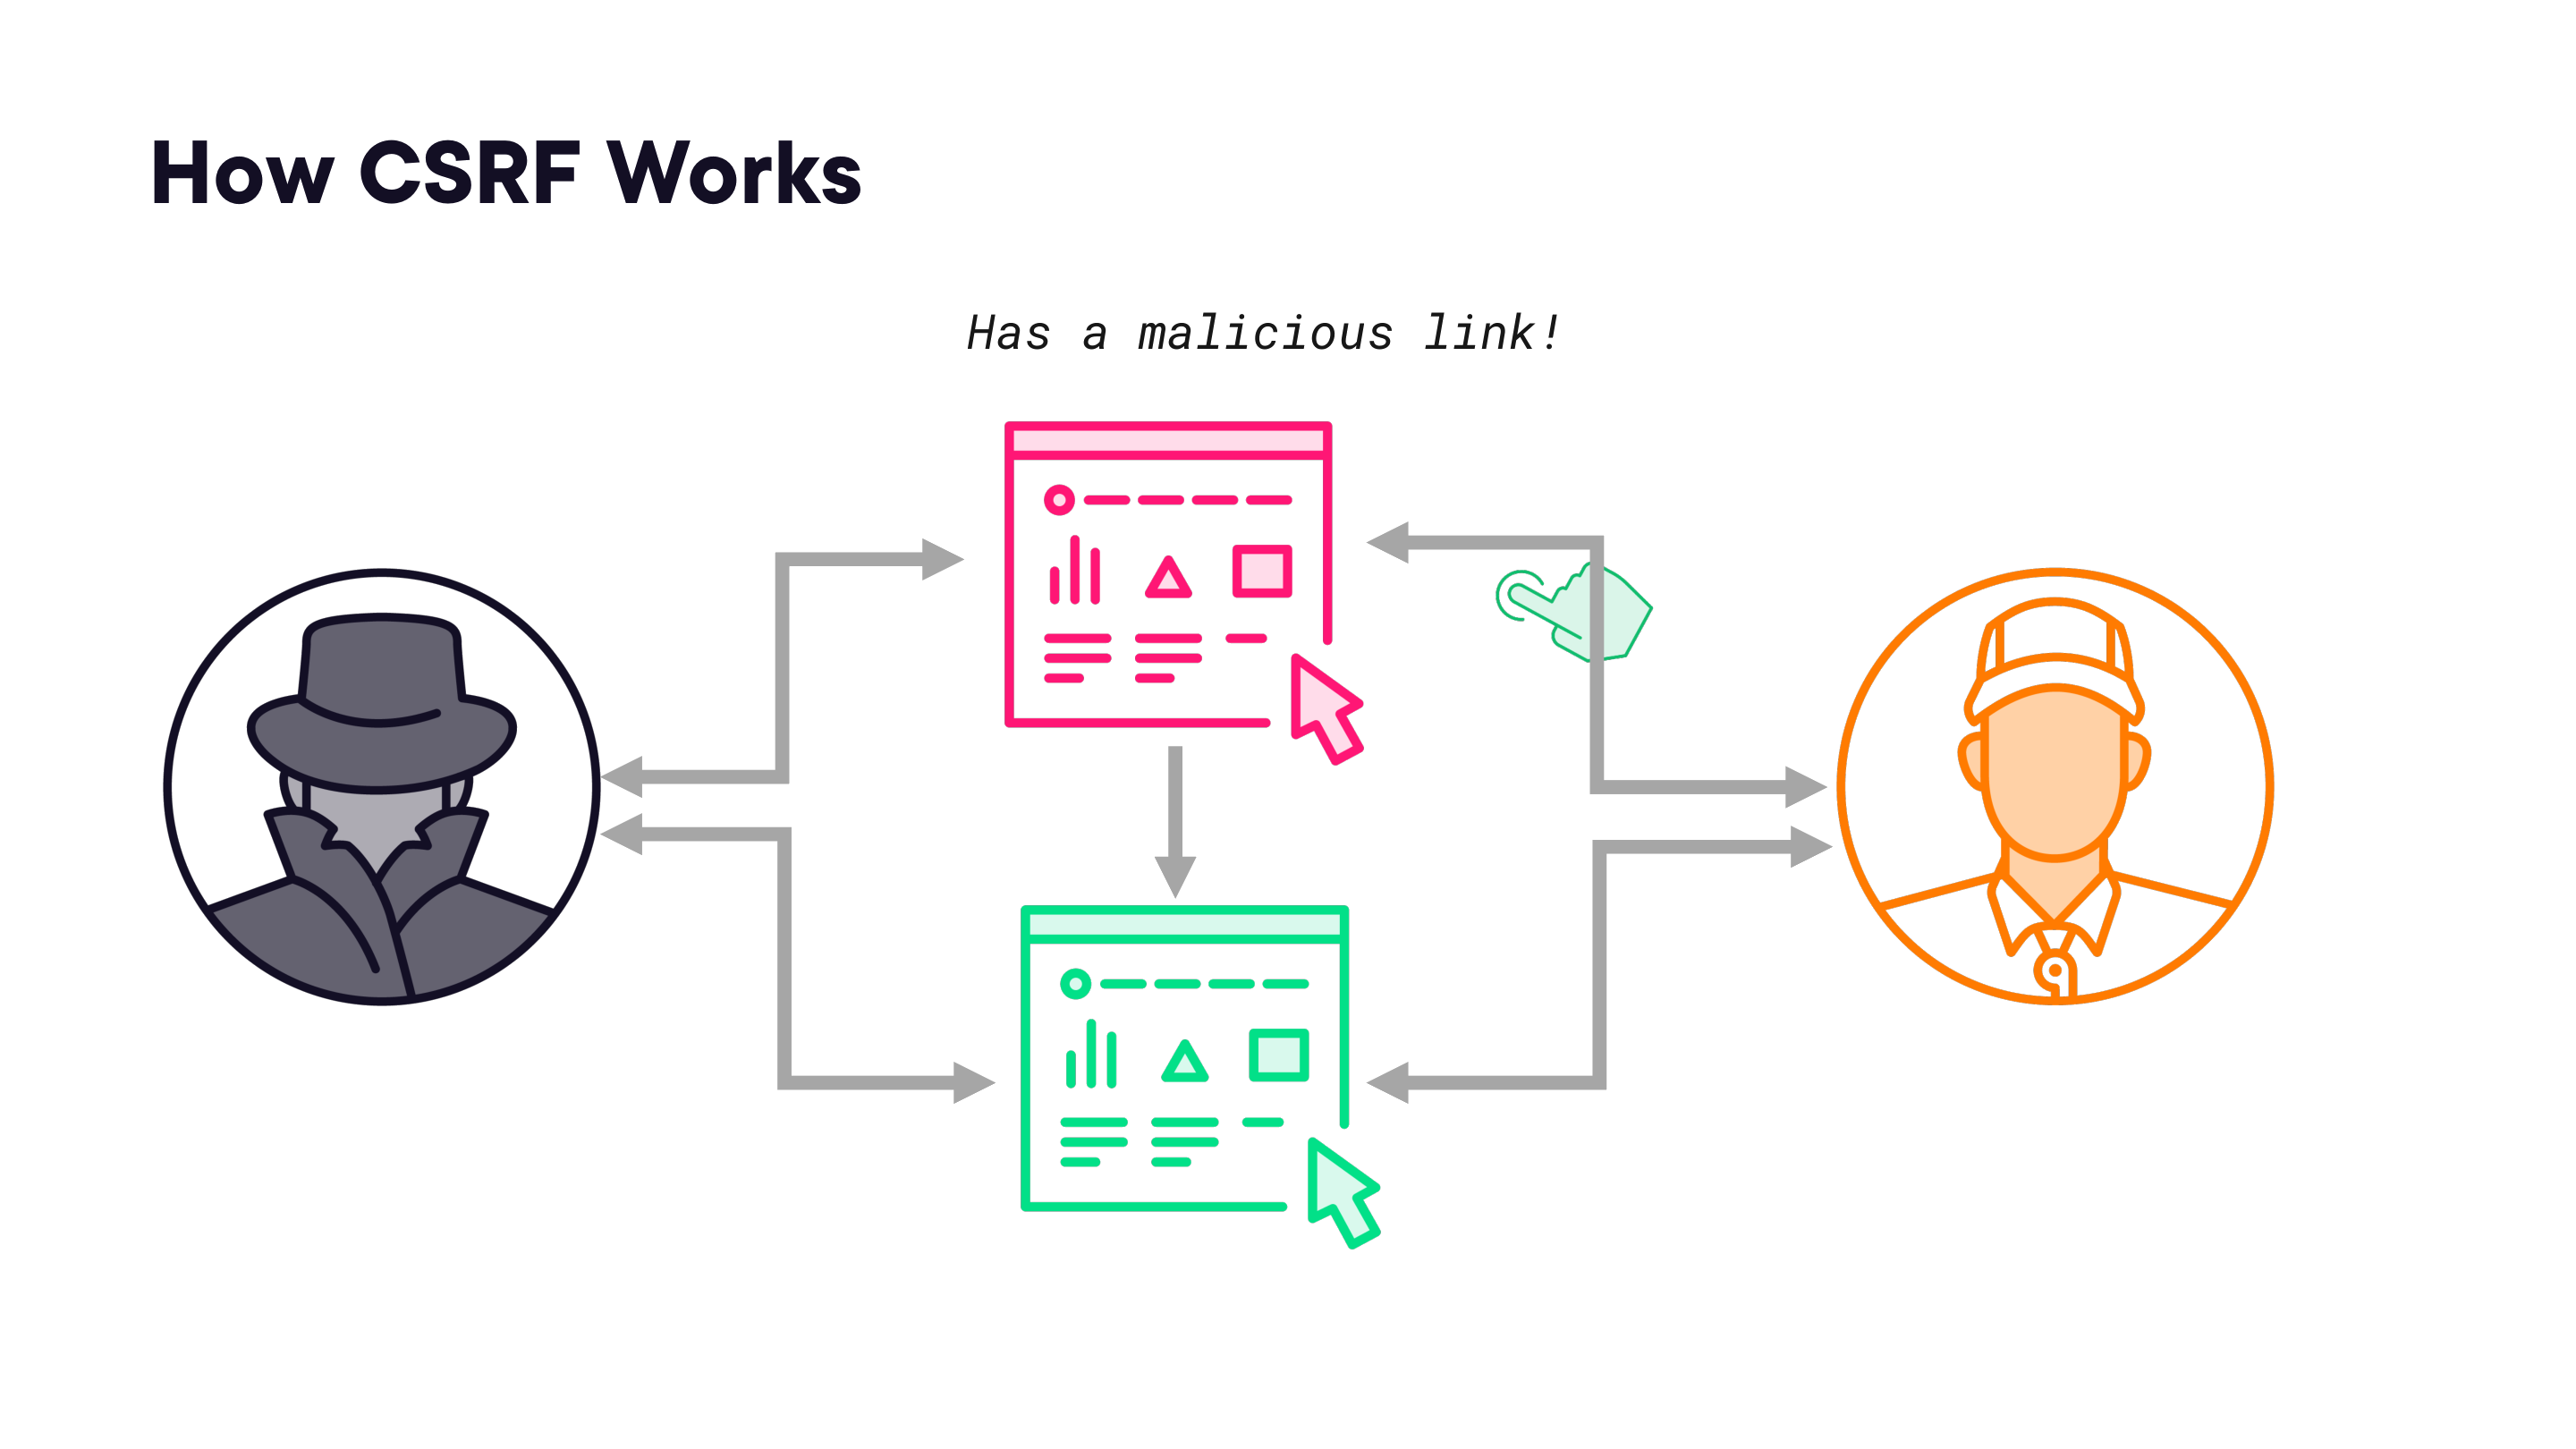

In [2]:
render_diagram(Path("assets/01-csrf-attack-flow.png"))

Django provides built-in CSRF protection that is activated by default via `CsrfViewMiddleware` in the `MIDDLEWARE` setting.

#### Using `{% csrf_token %}` in Templates

Every HTML form that submits data via POST must include the CSRF token tag:

```html
<form method="post">
  {% csrf_token %}
  ...
</form>
```

#### Per-view CSRF Decorators

```python
from django.views.decorators.csrf import csrf_exempt, csrf_protect

# Disable CSRF protection for a specific view (use with caution — e.g., for APIs with token auth)
@csrf_exempt
def my_view(request):
    return HttpResponse("Hello world")

# Explicitly enforce CSRF on a view (useful when CsrfViewMiddleware is disabled globally)
@csrf_protect
def my_view(request):
    ctx = {"data": {'name': 'example'}}
    return render(request, "a_template.html", ctx)
```

#### Session-based CSRF (`CSRF_USE_SESSIONS`)

```python
# settings.py
CSRF_USE_SESSIONS = True
```

When enabled, Django uses session-based protection instead of cookie-based. This is useful when your application is built as a stateless API where cookies are not appropriate.

### SQL Injection Prevention in Django 4

**SQL Injection (SQLi)** is a dangerous web vulnerability where an attacker manipulates SQL queries by injecting malicious input through application data fields.

#### How SQLi Happens

```python
# VULNERABLE — never do this
def search_by_title(request):
    query = request.GET.get("title")
    sql_stmt = f"SELECT * FROM POST WHERE title LIKE '{query}';"
    cursor = db.cursor()
    cursor.execute(sql_stmt)
    ...

# With input '%%' OR 'a'='a, this becomes:
# SELECT * FROM POST WHERE title LIKE '%%' OR 'a'='a';
# → returns the entire table
```

#### General Rules to Prevent SQLi

- **Never trust user-submitted data** — always treat it as potentially malicious
- **Always use parameterized statements** — they separate dynamic parameters from the SQL query structure
- Use a database client library that supports parameterized statements

#### SQLi Prevention in Django 4

Django's ORM uses parameterized statements by default, making most queries safe. However, be aware of:

- **CVE-2022-34265**: Django's `Trunc` and `Extract` functions were susceptible to SQL injection. Fixed in Django 4.0.6+/4.1+ — always keep Django updated.

**Cases requiring extra caution:**

- **Raw SQL queries** — when the ORM isn't expressive enough:
  ```python
  # Safe: use parameterized placeholders
  MyModel.objects.raw("SELECT * FROM myapp_mymodel WHERE title = %s", [user_input])
  ```
- **Custom ORM expressions/aggregates** — avoid string interpolation in custom expressions
- **Third-party ORM** (e.g., SQLAlchemy) — follow that library's parameterization guidelines

**Additional hardening:**
- Be cautious when including custom expressions or aggregates from third-party apps
- Pin your dependencies to prevent installation of newer, potentially less secure versions
- Avoid string interpolation in custom expressions
- Incorporate input sanitization and escaping where using raw SQL is unavoidable

### Clickjacking Prevention in Django 4

**Clickjacking** is an attack where an attacker loads an invisible page (via `<iframe>`) over a legitimate visible one. The user believes they are clicking a visible element but is actually triggering actions on the hidden page.

> The bank transfer page is displayed in an invisible iframe above the free gift page, with the "Confirm Transfer" button exactly aligned over the "Receive Gift" button visible to the user.

#### Preventing Clickjacking

**1. Add `XFrameOptionsMiddleware` to your middleware stack:**

```python
# settings.py
MIDDLEWARE = [
    'django.middleware.security.SecurityMiddleware',
    'django.contrib.sessions.middleware.SessionMiddleware',
    'django.middleware.common.CommonMiddleware',
    'django.middleware.csrf.CsrfViewMiddleware',
    'django.middleware.clickjacking.XFrameOptionsMiddleware',  # ← add this
    'django.contrib.auth.middleware.AuthenticationMiddleware',
    'django.contrib.messages.middleware.MessageMiddleware',
]
```

This middleware sets the `X-Frame-Options` header on all responses. You can also set `X_FRAME_OPTIONS = 'DENY'` in settings to control the default.

**2. Override the default on a per-view basis:**

```python
from django.views.decorators.clickjacking import (
    xframe_options_exempt,   # allow loading in any iframe
    xframe_options_deny,     # never allow iframing
    xframe_options_sameorigin,  # allow iframing only from same origin
)

@xframe_options_exempt
def load_within_iframe(request):
    return HttpResponse("Load me within an iFrame!")
```

### Host Header Validation in Django 4

Django uses the HTTP `Host` header to construct fully qualified URLs. A malicious `Host` header could cause the application to load page resources from a different domain.

**Attacks prevented by host header validation:**
- CSRF attacks via crafted URLs
- Email link poisoning (e.g., password reset links pointing to attacker domain)
- Cache poisoning attacks

#### `ALLOWED_HOSTS` Setting

```python
# settings.py
DEBUG = True
ALLOWED_HOSTS = ["futurewatch.me", "www.futurewatch.me"]
```

Rules:
- Takes fully qualified names like `www.example.com`
- A value beginning with `.` matches as a subdomain wildcard (e.g., `.example.com` matches `foo.example.com`)
- Values are sanitized to prevent Cross-Site Scripting attacks
- `django.http.HttpRequest.get_host()` raises `SuspiciousOperation` if the host is not in `ALLOWED_HOSTS`

Use `request.META['HTTP_HOST']` to implement custom host-header behavior when needed.

### Verifying User-uploaded Content

User content arrives through two main channels:

**Web Forms:**
- Most end users submit content via HTML forms
- Forms that handle file uploads require `enctype="multipart/form-data"` and `method="POST"`
- Validate content first on the client side, then enforce validation in Django views

**File Uploads:**
- Uploaded files arrive in `request.FILES`
- Django provides `FileField` and `ImageField` model fields for file uploads
- Configure `MEDIA_URL` and `MEDIA_ROOT` in settings to define storage location

```python
# settings.py
MEDIA_URL = '/media/'
MEDIA_ROOT = BASE_DIR / 'media'
```

#### Security Measures for User-uploaded Content

- **Limit upload size** in your server configuration (e.g., `client_max_body_size` in Nginx)
- **Disable static file execution** — disable handlers like `mod_php` on Apache to prevent executing uploaded scripts
- **Verify files before serving** — validate file type and content before making them accessible to users
- **Serve from a separate domain** — serve user-uploaded content from a distinct top-level or second-level domain to isolate it from your application's cookie scope
- **Allowlist file extensions** — define specific permissible extensions and configure the server to block others

## Module 03: Optimizing Django 4 for Speed and Scalability

This module explores Django 4's performance optimization toolkit: caching strategies, database query optimization with `django-debug-toolbar`, and template rendering improvements.

### Caching in Django 4

**Caching** involves storing frequently accessed data in temporary storage to enhance performance by avoiding repetitive computations and database queries.

> "Programmers have spent far too much time worrying about efficiency in the wrong places and at the wrong times; premature optimization is the root of all evil in programming." — Donald Knuth

Performance is still a key feature: bad performance negatively impacts users and revenue. The goal is to identify *where* performance issues actually arise before optimizing.

#### Per-view Caching

Cache the entire output of a view using the `cache_page` decorator:

```python
from django.views.decorators.cache import cache_page

@cache_page(60 * 15)  # cache for 15 minutes
def my_view(request):
    ...
```

#### Template Fragment Caching

Cache only specific sections of a template using the `{% cache %}` tag:

```html
{% load cache %}
{% cache 500 footer %}
  .. Footer ..
{% endcache %}
```

#### Low-level Cache API

For caching arbitrary data (query results, computed values):

```python
from django.core.cache import cache

def my_function():
    my_data = cache.get('my_data')
    if my_data is None:
        # Expensive computation or database query
        my_data = ...
        cache.set('my_data', my_data, 3600)  # cache for 1 hour
    return my_data
```

#### Multiple Caching Backends

Django supports multiple cache backends:

- **Memcached** — fast, in-memory key-value store; most commonly used
- **Redis** — in-memory data structure store; supports persistence and tagging
- **Cache tagging** — a way to group related cache entries for targeted invalidation

#### Caching Summary

Django's caching system can significantly improve performance by:
- Caching frequently accessed data to avoid repeated computation
- Minimizing database queries
- Using cache strategies tailored to specific application requirements

### Database Query Optimization

The biggest challenge in Django optimization is ensuring your database works efficiently. A slow database will slow down your entire site.

#### Identifying Performance Issues: django-debug-toolbar

`django-debug-toolbar` provides detailed information about SQL queries at your site, letting you quickly identify performance problems:

```bash
pip install django-debug-toolbar
```

```python
# settings.py
INSTALLED_APPS = [
    ...
    'debug_toolbar',
]
MIDDLEWARE = [
    'debug_toolbar.middleware.DebugToolbarMiddleware',
    ...
]
INTERNAL_IPS = ['127.0.0.1']

# urls.py
import debug_toolbar
urlpatterns = [
    path('__debug__/', include(debug_toolbar.urls)),
    ...
]
```

#### Reducing the Number of Queries

Django's ORM provides two key methods to minimize queries when accessing related objects:

```python
# select_related — fetches related objects in a single JOIN query (for ForeignKey/OneToOne)
articles = Article.objects.select_related('author').all()

# prefetch_related — fetches related objects in separate queries then caches them (for ManyToMany/reverse FK)
articles = Article.objects.prefetch_related('tags').all()
```

#### Identifying Slow Queries

Common patterns that indicate slow queries:
- **Missing values** — queries returning unexpected NULLs may indicate missing joins
- **Expensive table joins** — excessive JOINs on large tables
- **Queries that grab too many results** — unbounded `SELECT *` without `LIMIT`
- **Avoid database counts** — `COUNT(*)` on large tables is expensive; consider caching counts
- **Consider alternatives to generic foreign keys** — `GenericForeignKey` disables query optimization
- **Utilize methods like `defer`, `only`, `values`** — load only the columns you need

```python
# Only load specific fields
Article.objects.only('title', 'published_date')

# Defer loading of large text fields
Article.objects.defer('content')

# Return dicts instead of model instances (faster for read-only access)
Article.objects.values('title', 'published_date')
```

#### Alternate Data Stores

For specific use cases, consider alternatives to the relational database:
- **Elasticsearch** — full-text search with better performance than `LIKE` queries
- **Redis** — high-performance key-value store for session data, counters, queues

### Template Rendering Performance

**Django templates** are the most common way to dynamically generate HTML. A template consists of the static HTML structure plus syntax for inserting dynamic content.


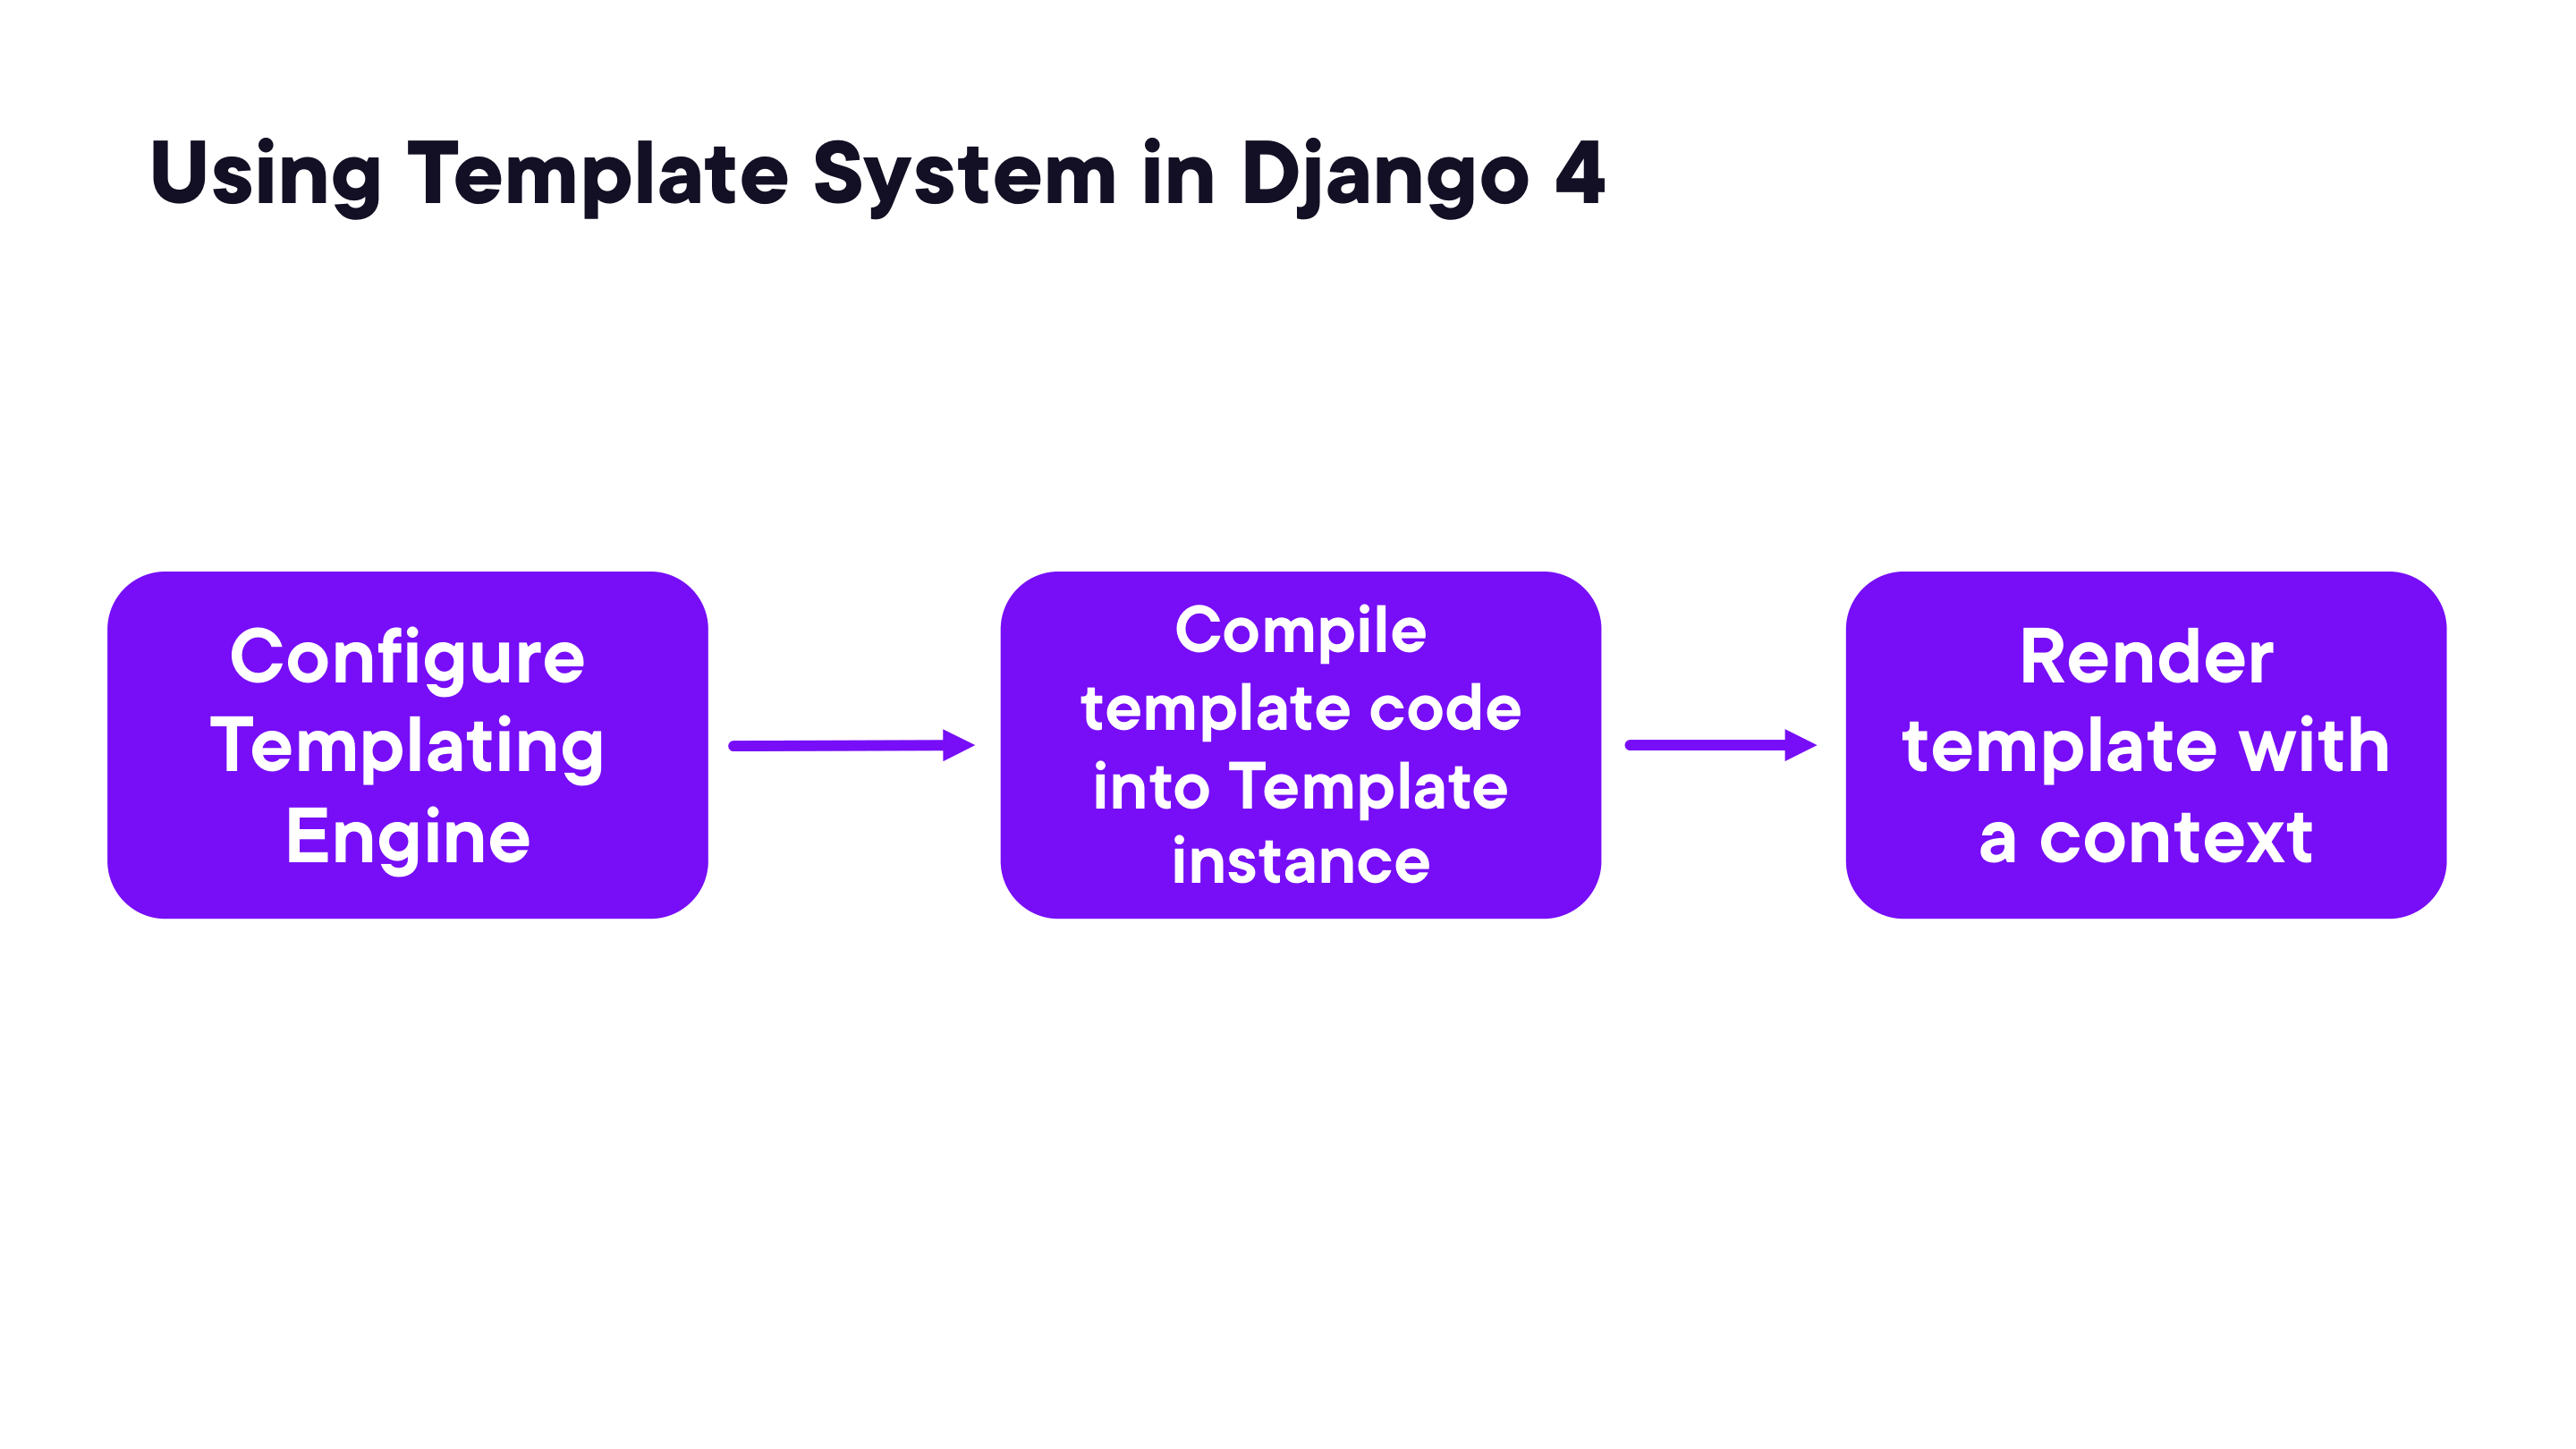

In [3]:
render_diagram(Path("assets/02-template-system-pipeline.png"))

Templates involve compilation when rendering dynamic content — this compilation cost can become significant at scale.

Use `django-debug-toolbar-template-profiler` to measure template rendering performance:

```bash
pip install django-debug-toolbar-template-profiler
```

#### Tweaks for Faster Template Rendering

**1. Switch to Jinja2**
- An alternative templating engine that can be faster in some benchmarks
- Comes with new challenges and does not resolve all performance issues

**2. Use the `{% cache %}` template tag**
Cache expensive template fragments to avoid re-rendering them on every request.

**3. Front-end optimization**
Think of backend servers as one piece of the end-user experience. It has been observed that Django sites can render pages in less than 200ms on the backend, but take 7 seconds to load in the browser — the bottleneck is often front-end assets.

**4. Treat CSS and JavaScript files like database queries**
- Cache static files aggressively
- Use asset pipeline tools: `django-pipeline`, `django-compressor`, `webassets`
- Ensure versioning of static files to prevent browsers from serving stale cached versions

**5. Media optimization**
- Optimize images with tools like `pngcrush`
- Use `easy-thumbnails` or similar for thumbnail optimization
- Serve static files via a CDN (Content Delivery Network)
- Consider cloud storage solutions (Amazon S3, GCP Storage) for static file hosting

#### More Template Optimization Tweaks

- **Feed Unicode to the templating engine** instead of byte strings
- **Prefer `{% block %}` over `{% include %}`** — `block` is faster because it avoids template compilation overhead
- **Mark variables as `safe`** when you know they contain no user-controlled HTML (`{{ var|safe }}`)
- **Avoid complex inheritance** — deep nesting and multiple inheritance levels add compilation cost
- **Use JavaScript to defer non-visible elements** — lazy-load content below the fold
- **Minimize endless pagination** — cursor-based or keyset pagination is more efficient than `OFFSET`

#### Cached Template Loading

Use Django's built-in cached template loader to cache template compilation:

```python
# settings.py
TEMPLATES = [{
    'BACKEND': 'django.template.backends.django.DjangoTemplates',
    'DIRS': [BASE_DIR / 'templates'],
    'OPTIONS': {
        'loaders': [
            ('django.template.loaders.cached.Loader', [
                'django.template.loaders.filesystem.Loader',
                'django.template.loaders.app_directories.Loader',
            ]),
        ],
    },
}]
```

This compiles each template once and caches it in memory, eliminating repeated compilation on every request.

### Memcached in Django 4

**Memcached** is a fast, distributed in-memory caching system widely used in web applications:
- Stores data in memory, making it faster than disk-based caching
- Reduces database load and API calls
- Does **not** persist data — if Memcached restarts, the cache is empty and must be repopulated

**Installation:**
```bash
# Server
brew install memcached  # macOS
# or: sudo apt install memcached  # Ubuntu

# Python client
pip install pymemcache
```

#### Configuring Memcached in Django

```python
# settings.py
CACHES = {
    'default': {
        'BACKEND': 'django.core.cache.backends.memcached.PyMemcacheCache',
        'LOCATION': '127.0.0.1:11211',
    }
}
```

#### Caching Database Query Results

```python
from django.core.cache import cache

def news_article_list(request):
    cache_key = 'news_article_list'
    news_articles = cache.get(cache_key)
    if not news_articles:
        news_articles = NewsArticle.objects.all()
        cache.set(cache_key, news_articles)
    return render(request, 'news/news_article_list.html', {'news_articles': news_articles})
```

#### Cache Invalidation

When data changes, invalidate the relevant cache entries to prevent stale data:

```python
from django.core.cache import cache

def update_news_article(request, article_id):
    article = get_object_or_404(NewsArticle, id=article_id)
    # ... update the article in the database ...

    # Invalidate the cache for this specific article
    cache_key = f"news_article_{article_id}"
    cache.delete(cache_key)
```

Use a consistent prefix convention for cache keys to make invalidation predictable.

#### Memcached Summary

Memcached caching improves application performance by:
- Reducing database queries and enhancing response times
- Optimizing resource consumption
- Enhancing user experience through faster page loads

Its easy integration and widespread adoption make it a valuable tool for optimizing Django applications.

## Module 04: Conclusion and Next Steps

This module summarizes the key topics covered in the course and outlines paths for continued learning.

### Course Summary

**Module 01 — Django 4 Basics:**
- Set up a virtual environment and install Django 4
- Create and run a Django project
- Deploy to a cloud platform via GitHub

**Module 02 — Security:**
- Configured SSL/HTTPS using Let's Encrypt and Certbot
- Implemented CSRF protection with middleware, template tags, and decorators
- Prevented SQL injection using Django's ORM parameterized queries
- Added clickjacking protection via `XFrameOptionsMiddleware`
- Applied host header validation with `ALLOWED_HOSTS`
- Verified user-uploaded content with proper field types and server configuration

**Module 03 — Performance:**
- Used caching (per-view, fragment, low-level API, Memcached) to reduce database load
- Identified bottlenecks with `django-debug-toolbar`
- Optimized database queries with `select_related`, `prefetch_related`, `defer`, `only`, `values`
- Improved template rendering with cached loaders, front-end optimization, and CDNs

### What's Next?

**Apply the knowledge:**
- Implement the security and performance techniques in your own Django projects
- Apply best practices to secure your applications and optimize their performance

**Stay up to date:**
- Follow the official Django documentation for updates and new features
- Engage with the Django community and stay current with releases

**Expand your skill set:**
- Explore adjacent technologies: Django REST Framework, Celery, channels (WebSockets)
- Broaden into related areas: containerization (Docker), CI/CD pipelines, cloud infrastructure

**Share and collaborate:**
- Participate in Django forums (Django Forum, Stack Overflow)
- Contribute to open-source Django packages